# 06 · Benchmarks: SVM and KNN
**Paper:** Sec. V A, Fig. 4, Tables VI–VII  
Linear SVC with C = 0.1; KNN with k = 18, uniform weights, Manhattan metric (GME) and k = 20, distance weights, Euclidean metric (SLOCC). Trained on the simulated set, scored on all 30 experimental states.  
**Code:** `ann_entanglement.models`, `ann_entanglement.experiments.baselines`

In [1]:
import os, sys
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
sys.path.insert(0, os.path.abspath("../src"))  # not needed after `pip install -e .`
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)

In [2]:
from ann_entanglement import experiments
train, exp_x = experiments.prepare(n_per_class=2000, seed=0)
b_gme = experiments.baselines('gme', train, exp_x); b_slocc = experiments.baselines('slocc', train, exp_x)
pd.concat({'GME': b_gme.set_index('N'), 'SLOCC': b_slocc.set_index('N')}, axis=1)

GME         SLOCC       
   A1_svm A2_knn A1_svm A2_knn
N                             
1   0.833  0.400  0.333  0.233
2   0.900  0.533  0.333  0.400
3   0.933  0.767  0.333  0.367
4   0.967  0.900  0.567  0.400
5   0.900  0.967  0.767  0.700
6   0.900  0.967  0.833  0.633
7   0.900  0.967  0.833  0.700
8   0.933  0.967  0.833  0.767
9   0.967  0.967  0.833  0.800
10  0.933  0.967  0.800  0.733
11  0.933  0.967  0.800  0.767
12  0.933  0.967  0.800  0.733
13  0.933  1.000  0.800  0.733
14  0.933  1.000  0.800  0.733
15  0.933  1.000  0.800  0.700
16  0.933  1.000  0.800  0.733
17  0.933  1.000  0.800  0.733
18  0.933  1.000  0.800  0.800

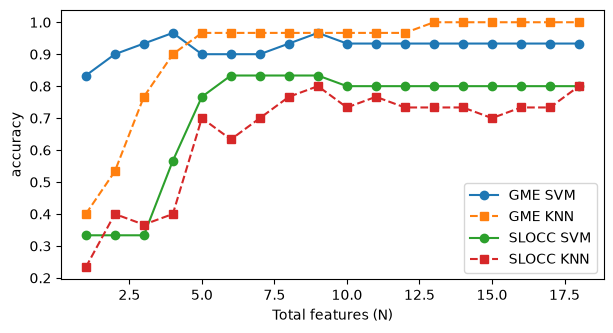

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for lab, b in (('GME', b_gme), ('SLOCC', b_slocc)):
    ax.plot(b.N, b.A1_svm, 'o-', label=f'{lab} SVM'); ax.plot(b.N, b.A2_knn, 's--', label=f'{lab} KNN')
ax.set_xlabel('Total features (N)'); ax.set_ylabel('accuracy'); ax.legend(); plt.show()